## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresadebe de realizar mantenimiento técnico y necesita llevar sus tareas según su prioridad, atendiendo siempre primero la más urgente y conectar seis dispositivos usando la menor cantidad de largo total de cable. Para lo primero se implementa una Max-Priority Queue con un Max-Heap, para lo segundo se calcula el Árbol de Expansión Mínima MST con el algoritmo de Kruskal.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

Funcionales
- RF1: Construir un max-heap a partir de la lista de tareas build-max-heap.
- RF2: Extraer la tarea de mayor prioridad de extract-max.
- RF3: Insertar nuevas tareas manteniendo la propiedad del max-heap.
- RF4: Calcular la distancia euclidiana entre cada pareja de dispositivos.
- RF5: Calcular el MST con Kruskal y mostrar las conexiones y la longitud total.
- RF6: Graficar los dispositivos y el MST con sus pesos.
 
No funcionales
- RNF1: No usar heapq ni funciones de librerías que calculen el MST.
- RNF2: Todo el desarrollo en un único Notebook, completamente ejecutado.
- RNF3: Código legible y comentado.




## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.

HU1:Como administrador quiero ver las tareas ordenadas en un max-heap para saber cuál atender primero.
- Criterios:el elemento raíz tiene la mayor prioridad: todo padre >= sus hijos.
 
HU2:Como técnico quiero extraer la tarea más urgente para procesarla de inmediato.
- Criterios:se muestra la tarea procesada: el heap resultante sigue siendo válido.
 
HU3:Como administrador quiero agregar una tarea urgente nueva para atender emergencias.
- Criterios:la tarea queda en la posición correcta: se conserva la propiedad max-heap.
 
HU4:Como ingeniero de redes quiero conectar los dispositivos con la menor cantidad de cable para reducir costos.
- Criterios:el MST tiene exactamente 5 aristas: no hay ciclos, se muestra la longitud total.
 
HU5:Como jefe técnico quiero ver gráficamente la red final para validar la solución.
- Criterios:se ven los 6 dispositivos solo las aristas del MST y sus pesos.

## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general
Adjunta imagen y descríbelo claramente.


![Blank diagram.png](<attachment:Blank diagram.png>)


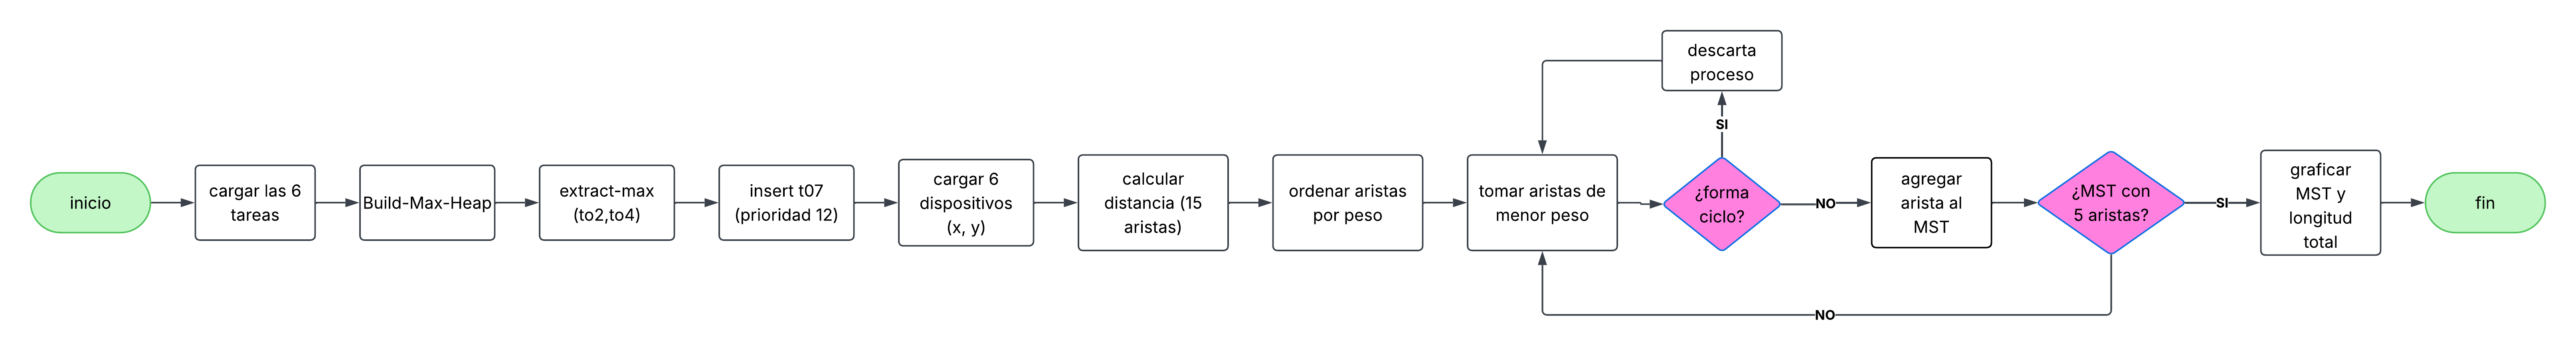

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica

![Captura de pantalla 2026-11-24 103843.png](<attachment:Captura de pantalla 2026-11-24 103843.png>)

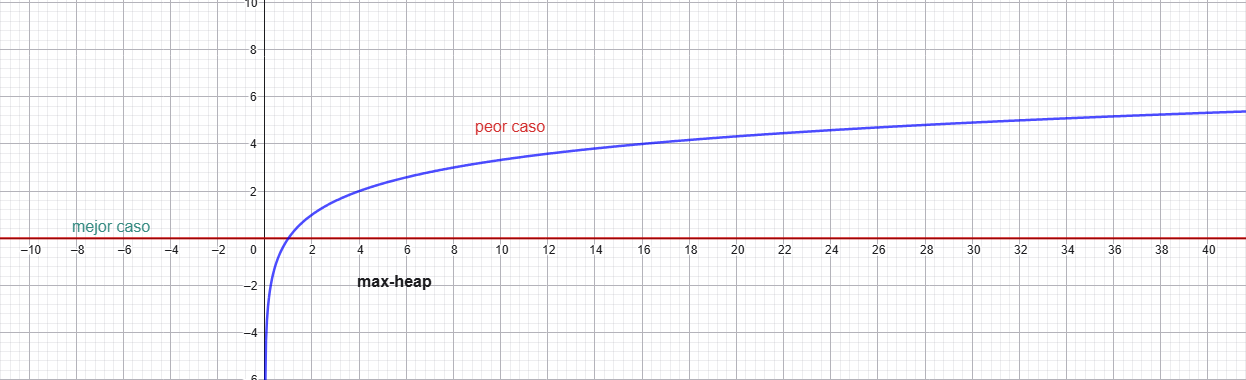

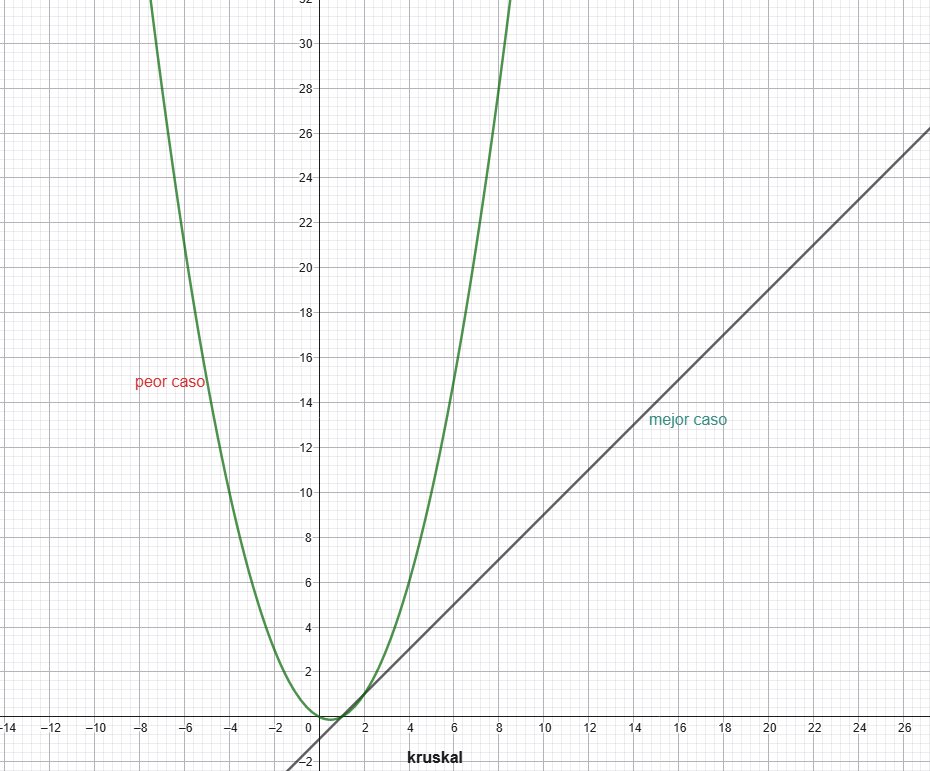

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:
import math
import matplotlib.pyplot as plt
 

def max_heapify(A, i, n):
    l, r, m = 2*i + 1, 2*i + 2, i
    if l < n and A[l][0] > A[m][0]: m = l
    if r < n and A[r][0] > A[m][0]: m = r
    if m != i:
        A[i], A[m] = A[m], A[i]
        max_heapify(A, m, n)
 
def build_max_heap(A):
    for i in range(len(A) // 2 - 1, -1, -1):
        max_heapify(A, i, len(A))
 
def extract_max(A):
    mayor = A[0]
    A[0] = A[-1]
    A.pop()
    max_heapify(A, 0, len(A))
    return mayor
 
def insert(A, t):
    A.append(t)
    i = len(A) - 1
    while i > 0 and A[(i-1)//2][0] < A[i][0]:
        A[i], A[(i-1)//2] = A[(i-1)//2], A[i]
        i = (i-1)//2
 
def mostrar(A):
    print([f"{c}({p})" for p, c, _ in A])
 
def arbol(A):                    
    ini, tam, nivel = 0, 1, 0
    while ini < len(A):
        print(f"  Nivel {nivel}:", [f"{c}({p})" for p, c, _ in A[ini:ini+tam]])
        ini += tam; tam *= 2; nivel += 1
 
tareas = [(6, "T01", "Configurar servidor"), (10, "T02", "Reparar sensor"),
          (4, "T03", "Actualizar software"), (8, "T04", "Revisar cámara"),
          (3, "T05", "Generar respaldo"),    (7, "T06", "Configurar alarma")]
 
print("Arreglo inicial:"); mostrar(tareas)
build_max_heap(tareas)
print("\nMax-Heap:"); mostrar(tareas)
print("Árbol:"); arbol(tareas)
 
for _ in range(2):
    p, c, nombre = extract_max(tareas)
    print(f"\nProcesada: {c} - {nombre} (prioridad {p})")
    print("Heap:"); mostrar(tareas)
 
insert(tareas, (12, "T07", "Falla en sistema contra incendios"))
print("\nHeap tras insertar T07:"); mostrar(tareas)
print("Árbol:"); arbol(tareas)
 
# ===== PUNTO 3: DISPOSITIVOS Y DISTANCIAS =====
disp = {"A": (2, 2), "B": (7, 3), "C": (4, 7),
        "D": (10, 8), "E": (13, 3), "F": (15, 7)}
 
aristas = []
ids = list(disp)
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        a, b = ids[i], ids[j]
        d = math.sqrt((disp[b][0]-disp[a][0])**2 + (disp[b][1]-disp[a][1])**2)
        aristas.append((d, a, b))
 
print("\nDistancias:")
for d, a, b in aristas:
    print(f"{a} - {b} : {d:.2f}")
 
for k, (x, y) in disp.items():
    plt.scatter(x, y, s=100, color="tab:blue")
    plt.text(x + 0.3, y + 0.3, k)
plt.title("Dispositivos"); plt.grid(True); plt.show()
 

aristas.sort()                              
grupo = {d: d for d in disp}                
mst, total = [], 0
for d, a, b in aristas:
    if grupo[a] != grupo[b]:               
        mst.append((a, b, d))               
        total += d
        viejo = grupo[b]
        for k in grupo:                     
            if grupo[k] == viejo:
                grupo[k] = grupo[a]
    if len(mst) == len(disp) - 1:           
        break
 
print("\nMST:")
for a, b, d in mst:
    print(f"{a} - {b} : {d:.2f}")
print(f"Longitud total de cable: {total:.2f}")
 

for a, b, d in mst:
    x1, y1 = disp[a]; x2, y2 = disp[b]
    plt.plot([x1, x2], [y1, y2], color="tab:red")
    plt.text((x1+x2)/2, (y1+y2)/2, f"{d:.2f}")
for k, (x, y) in disp.items():
    plt.scatter(x, y, s=100, color="tab:blue", zorder=3)
    plt.text(x + 0.3, y + 0.3, k)
plt.title(f"MST - Longitud total: {total:.2f}"); plt.grid(True); plt.show()
 


## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
